# Credit Risk Classification

For A/B tests, slides explanation, previous drafts and any further detail, kindly request access at: [GitHub repository](https://github.com/Klopi710/Credit-Risk-Classification)

#### 1. Import data & libraries complete

In [21]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / 'src' / 'data_contract.py').exists() and (candidate / 'data' / 'raw').exists():
            return candidate
    raise FileNotFoundError('Could not locate the assignment project root')

ROOT = find_project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data_contract import load_raw_data, make_xy, contract_summary, NUMERIC_COLUMNS, CATEGORICAL_COLUMNS

RAW_PATH = ROOT / 'data' / 'raw' / 'SouthGermanCredit.asc'
frame = load_raw_data(RAW_PATH)
print(f'Loaded raw source: {RAW_PATH}')
print(f'Rows: {len(frame)} | columns: {frame.shape[1]}')
display(frame.head())

Loaded raw source: c:\Users\katom\iCloudDrive\Smaller Creator\Sky\Marc Torrens Assignment\data\raw\SouthGermanCredit.asc
Rows: 1000 | columns: 21


,laufkont,laufzeit,moral,verw,hoehe,sparkont,beszeit,rate,famges,buerge,...,verm,alter,weitkred,wohn,bishkred,beruf,pers,telef,gastarb,kredit
0,1,18,4,2,1049,1,2,4,2,1,...,2,21,3,1,1,3,2,1,2,1
1,1,9,4,0,2799,1,3,2,3,1,...,1,36,3,1,2,3,1,1,2,1
2,2,12,2,9,841,2,4,2,2,1,...,1,23,3,1,1,2,2,1,2,1
3,1,12,4,0,2122,1,3,3,3,1,...,1,39,3,1,2,2,1,1,1,1
4,1,12,4,0,2171,1,3,4,3,1,...,2,38,1,2,2,2,2,1,1,1


---

#### 2. Train/test split

In [22]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 77
X_raw, y = make_xy(frame)
X_train, X_test, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

split_report = pd.DataFrame({
    'split': ['training/development', 'test/frozen'],
    'rows': [len(y_train), len(y_test)],
    'bad/default-risk': [int(y_train.sum()), int(y_test.sum())],
    'bad-risk rate': [y_train.mean(), y_test.mean()]
})
display(split_report)
print('Test and training sets are now separated; the test set is frozen.')

,split,rows,bad/default-risk,bad-risk rate
0,training/development,800,240,0.3
1,test/frozen,200,60,0.3


Test and training sets are now separated; the test set is frozen.


In [23]:
summary = contract_summary(frame)

assert frame.shape == (1000, 21)
assert frame['kredit'].isin([0, 1]).all()
assert frame.isna().sum().sum() == 0
assert frame.duplicated().sum() == 0
assert set(NUMERIC_COLUMNS) == {'laufzeit', 'hoehe', 'alter'}
assert len(CATEGORICAL_COLUMNS) == 17

assert_report = pd.DataFrame({
    'check': ['rows', 'columns', 'missing values', 'duplicate rows', 'bad/default-risk cases', 'good/performing cases'],
    'result': [summary['rows'], summary['columns'], summary['missing_values'], summary['duplicate_rows'], int(y.sum()), int((y == 0).sum())]
})
display(assert_report)
print('Proven: 1,000 rows, 20 predictors, no nulls, no duplicate rows, binary target, and the declared column contract.')
print('Positive class: bad/default-risk = raw kredit == 0 -> model target 1')

,check,result
0,rows,1000
1,columns,21
2,missing values,0
3,duplicate rows,0
4,bad/default-risk cases,300
5,good/performing cases,700


Proven: 1,000 rows, 20 predictors, no nulls, no duplicate rows, binary target, and the declared column contract.
Positive class: bad/default-risk = raw kredit == 0 -> model target 1


80/20 split leads to 800 training rows and 200 test rows.

---

#### 3. Context and target

In [24]:
feature_dictionary = {
    'laufkont': 'existing checking-account status', 'laufzeit': 'loan duration in months',
    'moral': 'credit history', 'verw': 'loan purpose', 'hoehe': 'credit amount',
    'sparkont': 'savings account or bonds', 'beszeit': 'employment duration',
    'rate': 'installment rate as percentage of disposable income', 'famges': 'personal status and sex code',
    'buerge': 'other debtors or guarantors', 'wohnzeit': 'years at present residence',
    'verm': 'property status', 'alter': 'age in years', 'weitkred': 'other installment plans',
    'wohn': 'housing status', 'bishkred': 'number of existing credits at this bank',
    'beruf': 'job category', 'pers': 'number of people financially liable for',
    'telef': 'telephone status', 'gastarb': 'foreign-worker code', 'kredit': 'historical credit-risk target'
}

column_table = pd.DataFrame({
    'english_column': [feature_dictionary[c] for c in frame.columns],
    'source_code': frame.columns,
    'role': ['target' if c == 'kredit' else 'predictor' for c in frame.columns],
    'type_used_by_model': ['target' if c == 'kredit' else ('numeric' if c in NUMERIC_COLUMNS else 'categorical') for c in frame.columns],
})

translation_path = ROOT / 'data' / 'processed' / 'SouthGermanCredit_column_translations.csv'
translation_path.parent.mkdir(parents=True, exist_ok=True)
column_table.to_csv(translation_path, index=False)

english_frame = frame.rename(columns=feature_dictionary)
english_sample_7 = english_frame.head(7)
print('English database sample: first 7 rows')
with pd.option_context('display.max_rows', 7, 'display.max_columns', None, 'display.width', 2400):
    display(english_sample_7)

codebook = {
    'laufkont': [(1, 'no checking account'), (2, '... < 0 DM'), (3, '0 <= ... < 200 DM'), (4, '... >= 200 DM / salary for at least 1 year')],
    'laufzeit': [('quantitative', 'loan duration in months')],
    'moral': [(0, 'delay in paying off in the past'), (1, 'critical account/other credits elsewhere'), (2, 'no credits taken/all credits paid back duly'), (3, 'existing credits paid back duly till now'), (4, 'all credits at this bank paid back duly')],
    'verw': [(0, 'other'), (1, 'new car'), (2, 'used car'), (3, 'furniture/equipment'), (4, 'radio/television'), (5, 'domestic appliances'), (6, 'repairs'), (7, 'education'), (8, 'vacation'), (9, 'retraining'), (10, 'business')],
    'hoehe': [('quantitative', 'credit amount in DM')],
    'sparkont': [(1, 'unknown/no savings account'), (2, '... < 100 DM'), (3, '100 <= ... < 500 DM'), (4, '500 <= ... < 1000 DM'), (5, '... >= 1000 DM')],
    'beszeit': [(1, 'unemployed'), (2, '< 1 year'), (3, '1 <= ... < 4 years'), (4, '4 <= ... < 7 years'), (5, '>= 7 years')],
    'rate': [(1, '>= 35%'), (2, '25 <= ... < 35%'), (3, '20 <= ... < 25%'), (4, '< 20%')],
    'famges': [(1, 'male: divorced/separated'), (2, 'female: non-single or male: single'), (3, 'male: married/widowed'), (4, 'female: single')],
    'buerge': [(1, 'none'), (2, 'co-applicant'), (3, 'guarantor')],
    'wohnzeit': [(1, '< 1 year'), (2, '1 <= ... < 4 years'), (3, '4 <= ... < 7 years'), (4, '>= 7 years')],
    'verm': [(1, 'unknown/no property'), (2, 'car or other'), (3, 'building society savings agreement/life insurance'), (4, 'real estate')],
    'alter': [('quantitative', 'age in years')],
    'weitkred': [(1, 'bank'), (2, 'stores'), (3, 'none')],
    'wohn': [(1, 'for free'), (2, 'rent'), (3, 'own')],
    'bishkred': [(1, '1 existing credit'), (2, '2-3 existing credits'), (3, '4-5 existing credits'), (4, '>= 6 existing credits')],
    'beruf': [(1, 'unemployed/unskilled - non-resident'), (2, 'unskilled - resident'), (3, 'skilled employee/official'), (4, 'manager/self-employed/highly qualified employee')],
    'pers': [(1, '3 or more people liable'), (2, '0 to 2 people liable')],
    'telef': [(1, 'no telephone'), (2, 'yes, under customer name')],
    'gastarb': [(1, 'yes, foreign worker'), (2, 'no, foreign worker')],
    'kredit': [(0, 'bad/default-risk'), (1, 'good/performing')],
}
reference_rows = []
for source_code, mappings in codebook.items():
    if mappings[0][0] == 'quantitative':
        values = frame[source_code]
        scalar_range = f'{int(values.min())}-{int(values.max())} (observed)'
        meaning_by_code = f'{mappings[0][1]} (measured quantity, not a category code)'
    else:
        numeric_codes = [int(code) for code, _ in mappings]
        scalar_range = f'{min(numeric_codes)}-{max(numeric_codes)}'
        meaning_by_code = '\n'.join(f'{code}: {meaning}' for code, meaning in mappings)
    reference_rows.append({
        'english_column': feature_dictionary[source_code],
        'source_code': source_code,
        'role': 'target' if source_code == 'kredit' else 'predictor',
        'type_used_by_model': 'target' if source_code == 'kredit' else ('numeric' if source_code in NUMERIC_COLUMNS else 'categorical'),
        'range': scalar_range,
        'meaning': meaning_by_code,
    })
column_reference_table = pd.DataFrame(reference_rows)
reference_table_path = ROOT / 'Mark' / 'Reference' / 'SouthGermanCredit_column_reference.csv'
reference_table_path.parent.mkdir(parents=True, exist_ok=True)
column_reference_table.to_csv(reference_table_path, index=False)
column_reference_table = pd.read_csv(reference_table_path)
column_reference_table = column_reference_table[['english_column', 'range', 'meaning', 'source_code', 'role', 'type_used_by_model']]
column_reference_table.to_csv(reference_table_path, index=False)
print('Translation table.')
with pd.option_context('display.max_rows', None, 'display.max_columns', None, 'display.max_colwidth', 1000, 'display.width', 6000):
    styled_reference_table = (
        column_reference_table.style
        .set_table_styles([
            {'selector': 'table', 'props': [('table-layout', 'fixed'), ('width', '100%')]},
            {'selector': 'th', 'props': [('text-align', 'left'), ('vertical-align', 'top')]},
            {'selector': 'th.col_heading.level0.col0, td.col0', 'props': [('width', '240px'), ('min-width', '240px')]},
            {'selector': 'th.col_heading.level0.col1, td.col1', 'props': [('width', '100px'), ('min-width', '100px')]},
            {'selector': 'th.col_heading.level0.col2, td.col2', 'props': [('width', '520px'), ('min-width', '520px')]},
            {'selector': 'th.col_heading.level0.col3, td.col3', 'props': [('width', '120px'), ('min-width', '120px')]},
            {'selector': 'th.col_heading.level0.col4, td.col4', 'props': [('width', '100px'), ('min-width', '100px')]},
            {'selector': 'th.col_heading.level0.col5, td.col5', 'props': [('width', '160px'), ('min-width', '160px')]},
        ], overwrite=False)
        .set_properties(
            subset=['english_column', 'range', 'meaning', 'source_code', 'role', 'type_used_by_model'],
            **{'white-space': 'normal', 'vertical-align': 'top', 'text-align': 'left'}
        )
        .set_properties(
            subset=['meaning'],
            **{'white-space': 'pre-wrap', 'overflow-wrap': 'anywhere'}
        )
    )
    display(styled_reference_table)

print('Original German-coded database: first 7 rows')
display(frame.head(7))
print('Dictionary')
display(column_table)

English database sample: first 7 rows


,existing checking-account status,loan duration in months,credit history,loan purpose,credit amount,savings account or bonds,employment duration,installment rate as percentage of disposable income,personal status and sex code,other debtors or guarantors,years at present residence,property status,age in years,other installment plans,housing status,number of existing credits at this bank,job category,number of people financially liable for,telephone status,foreign-worker code,historical credit-risk target
0,1,18,4,2,1049,1,2,4,2,1,4,2,21,3,1,1,3,2,1,2,1
1,1,9,4,0,2799,1,3,2,3,1,2,1,36,3,1,2,3,1,1,2,1
2,2,12,2,9,841,2,4,2,2,1,4,1,23,3,1,1,2,2,1,2,1
3,1,12,4,0,2122,1,3,3,3,1,2,1,39,3,1,2,2,1,1,1,1
4,1,12,4,0,2171,1,3,4,3,1,4,2,38,1,2,2,2,2,1,1,1
5,1,10,4,0,2241,1,2,1,3,1,3,1,48,3,1,2,2,1,1,1,1
6,1,8,4,0,3398,1,4,1,3,1,4,1,39,3,2,2,2,2,1,1,1


Translation table.


,english_column,range,meaning,source_code,role,type_used_by_model
0,existing checking-account status,1-4,1: no checking account 2: ... < 0 DM 3: 0 <= ... < 200 DM 4: ... >= 200 DM / salary for at least 1 year,laufkont,predictor,categorical
1,loan duration in months,4-72 (observed),"loan duration in months (measured quantity, not a category code)",laufzeit,predictor,numeric
2,credit history,0-4,0: delay in paying off in the past 1: critical account/other credits elsewhere 2: no credits taken/all credits paid back duly 3: existing credits paid back duly till now 4: all credits at this bank paid back duly,moral,predictor,categorical
3,loan purpose,0-10,0: other 1: new car 2: used car 3: furniture/equipment 4: radio/television 5: domestic appliances 6: repairs 7: education 8: vacation 9: retraining 10: business,verw,predictor,categorical
4,credit amount,250-18424 (observed),"credit amount in DM (measured quantity, not a category code)",hoehe,predictor,numeric
5,savings account or bonds,1-5,1: unknown/no savings account 2: ... < 100 DM 3: 100 <= ... < 500 DM 4: 500 <= ... < 1000 DM 5: ... >= 1000 DM,sparkont,predictor,categorical
6,employment duration,1-5,1: unemployed 2: < 1 year 3: 1 <= ... < 4 years 4: 4 <= ... < 7 years 5: >= 7 years,beszeit,predictor,categorical
7,installment rate as percentage of disposable income,1-4,1: >= 35% 2: 25 <= ... < 35% 3: 20 <= ... < 25% 4: < 20%,rate,predictor,categorical
8,personal status and sex code,1-4,1: male: divorced/separated 2: female: non-single or male: single 3: male: married/widowed 4: female: single,famges,predictor,categorical
9,other debtors or guarantors,1-3,1: none 2: co-applicant 3: guarantor,buerge,predictor,categorical


Original German-coded database: first 7 rows


,laufkont,laufzeit,moral,verw,hoehe,sparkont,beszeit,rate,famges,buerge,...,verm,alter,weitkred,wohn,bishkred,beruf,pers,telef,gastarb,kredit
0,1,18,4,2,1049,1,2,4,2,1,...,2,21,3,1,1,3,2,1,2,1
1,1,9,4,0,2799,1,3,2,3,1,...,1,36,3,1,2,3,1,1,2,1
2,2,12,2,9,841,2,4,2,2,1,...,1,23,3,1,1,2,2,1,2,1
3,1,12,4,0,2122,1,3,3,3,1,...,1,39,3,1,2,2,1,1,1,1
4,1,12,4,0,2171,1,3,4,3,1,...,2,38,1,2,2,2,2,1,1,1
5,1,10,4,0,2241,1,2,1,3,1,...,1,48,3,1,2,2,1,1,1,1
6,1,8,4,0,3398,1,4,1,3,1,...,1,39,3,2,2,2,2,1,1,1


Dictionary


,english_column,source_code,role,type_used_by_model
0,existing checking-account status,laufkont,predictor,categorical
1,loan duration in months,laufzeit,predictor,numeric
2,credit history,moral,predictor,categorical
3,loan purpose,verw,predictor,categorical
4,credit amount,hoehe,predictor,numeric
5,savings account or bonds,sparkont,predictor,categorical
6,employment duration,beszeit,predictor,categorical
7,installment rate as percentage of disposable i...,rate,predictor,categorical
8,personal status and sex code,famges,predictor,categorical
9,other debtors or guarantors,buerge,predictor,categorical


The task is to prioritise credit applications with historical bad-risk labels for enhanced manual review before the credit offer. The operating rule is exact top-20% risk ranking, subject to the 1,600-review monthly capacity.

The positive class is `bad/default-risk`. This equals the minority group we want to predict from our data: prospects with the historical bad-risk label.

The source dataset is in German. One row represents one credit application; the target records good/bad credit-risk outcome. The file is a dataset from the 1970s with 1,000 records.

The `good/bad` label is a historical credit-risk proxy, not an observed 12-month default outcome. Therefore, the model estimates historical bad-risk classification and the business values below are scenario assumptions, not measured causal default savings.

The numerical columns are loan duration in months, credit amount and age in years. Credit amount is much larger in raw units (roughly 250-18,424) than coded categorical variables (roughly 1-5). The pipeline scales numerical variables and one-hot encodes categorical variables.

Further data; 

![Business assumptions](../image/business_assumptions.png)


The code result presents the English-renamed 7-row sample first and fills the main output area. The original German-coded rows follow for provenance. The derived translation schema preserves both the source code and the English meaning without modifying the immutable raw file.

---

#### 4. Data cleaning

In [25]:
cleaning_report = pd.DataFrame({
    'check': ['missing cells', 'duplicate rows', 'constant predictors', 'unexpected target values'],
    'count': [
        int(frame.isna().sum().sum()),
        int(frame.duplicated().sum()),
        int(sum(frame[c].nunique() <= 1 for c in X_raw.columns)),
        int((~frame['kredit'].isin([0, 1])).sum()),
    ]
})
display(cleaning_report)
assert cleaning_report['count'].tolist() == [0, 0, 0, 0]
print('No cleaning decision is learned from the test distribution; no rows require removal or imputation.')
X_clean, y_clean = X_raw.copy(), y.copy()

,check,count
0,missing cells,0
1,duplicate rows,0
2,constant predictors,0
3,unexpected target values,0


No cleaning decision is learned from the test distribution; no rows require removal or imputation.


The source has no missing cells or duplicate rows. We check duplicates because one duplicated observation would receive artificial weight in the mean, mode, variance, and standard deviation. If imputation were needed, its values would be learned from training data only. Because the database was from a reputable source, it was likely well-prepared.

---

#### 5. Scaling and outliers

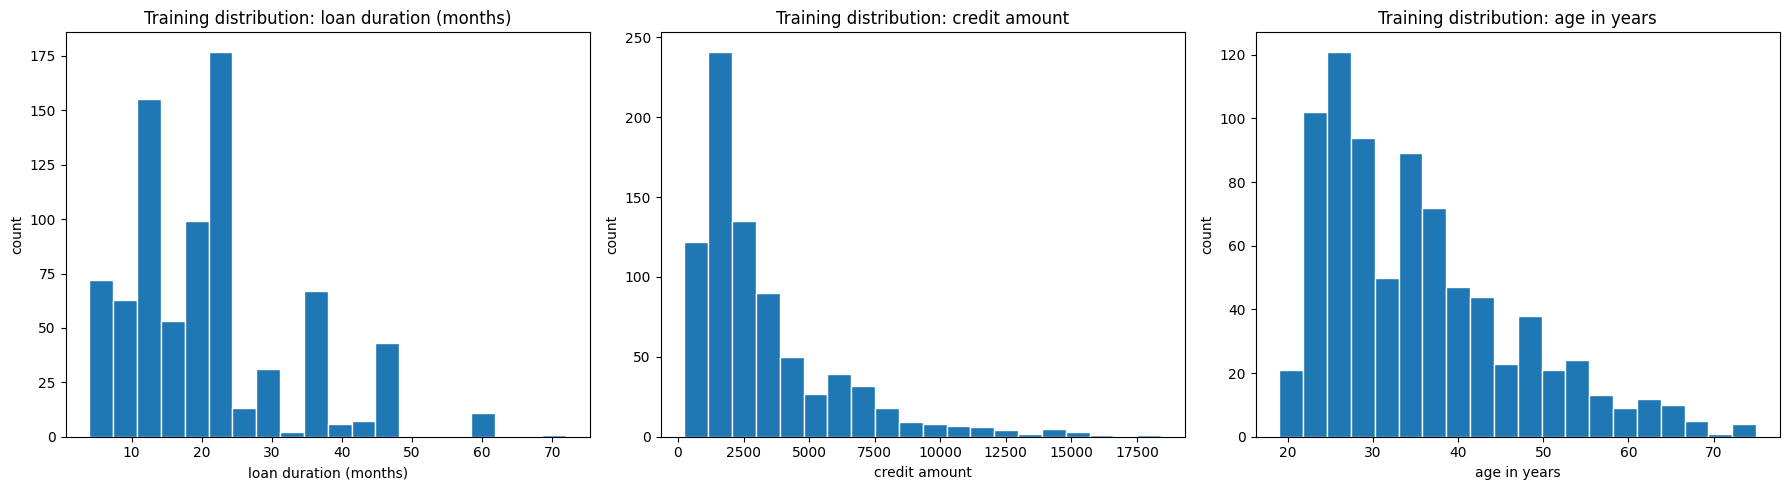

In [26]:
numeric_plot_columns = [
    ('laufzeit', 'loan duration (months)'),
    ('hoehe', 'credit amount'),
    ('alter', 'age in years'),
]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (column, english_name) in zip(axes, numeric_plot_columns):
    ax.hist(X_train[column], bins=20, edgecolor='white')
    ax.set_title(f'Training distribution: {english_name}')
    ax.set_xlabel(english_name)
    ax.set_ylabel('count')
plt.tight_layout()
plt.show()

,english_column,method,lower_bound,upper_bound,flagged_count,action
0,loan duration in months,IQR (1.5 x IQR),-6.0,42.0,55,inspect; do not delete automatically
1,credit amount,IQR (1.5 x IQR),-2639.5,8024.5,53,inspect; do not delete automatically
2,age in years,IQR (1.5 x IQR),2.0,66.0,10,inspect; do not delete automatically


,english_column,method,mean,std,flagged_count,action
0,loan duration in months,Z-score (|z| > 3),20.86625,12.011801,12,inspect; do not delete automatically
1,credit amount,Z-score (|z| > 3),3261.92000,2820.058073,19,inspect; do not delete automatically
2,age in years,Z-score (|z| > 3),35.37750,11.308846,5,inspect; do not delete automatically


All flagged training values saved to the reference files: 118 rows
Full Excel reference table: c:\Users\katom\iCloudDrive\Smaller Creator\Sky\Marc Torrens Assignment\Mark\Reference\SouthGermanCredit_flagged_values.xlsx
IQR reference sample: first 7 rows


,row_id,english_column,value,reference_range,method,iqr_flagged,z_score_flagged,review_decision
0,167,age in years,74,IQR: 2 to 66; z-score: 1.45096 to 69.304,IQR + z-score,True,True,valid-looking extreme; retained
1,259,age in years,74,IQR: 2 to 66; z-score: 1.45096 to 69.304,IQR + z-score,True,True,valid-looking extreme; retained
2,422,age in years,68,IQR: 2 to 66; z-score: 1.45096 to 69.304,IQR,True,False,valid-looking extreme; retained
3,452,age in years,70,IQR: 2 to 66; z-score: 1.45096 to 69.304,IQR + z-score,True,True,valid-looking extreme; retained
4,479,age in years,67,IQR: 2 to 66; z-score: 1.45096 to 69.304,IQR,True,False,valid-looking extreme; retained
5,602,age in years,75,IQR: 2 to 66; z-score: 1.45096 to 69.304,IQR + z-score,True,True,valid-looking extreme; retained
6,624,age in years,75,IQR: 2 to 66; z-score: 1.45096 to 69.304,IQR + z-score,True,True,valid-looking extreme; retained


,split,loan duration <= 0,credit amount <= 0,age <= 0
0,full raw data,0,0,0
1,training,0,0,0
2,test,0,0,0


Decision: retain valid extreme values; no outliers are removed automatically.


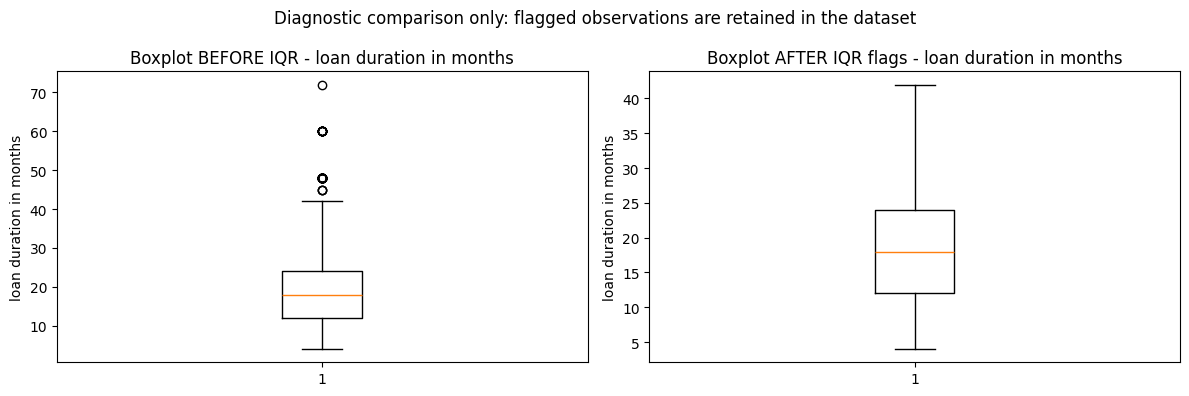

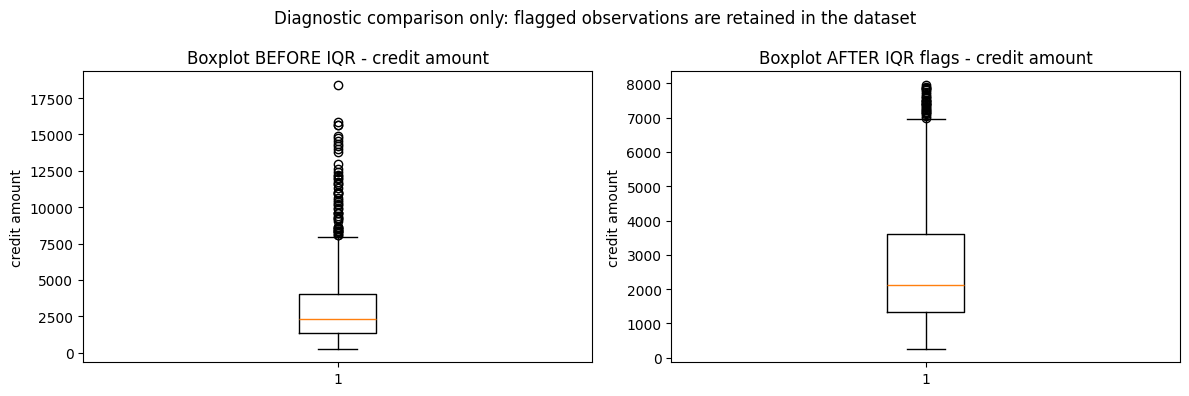

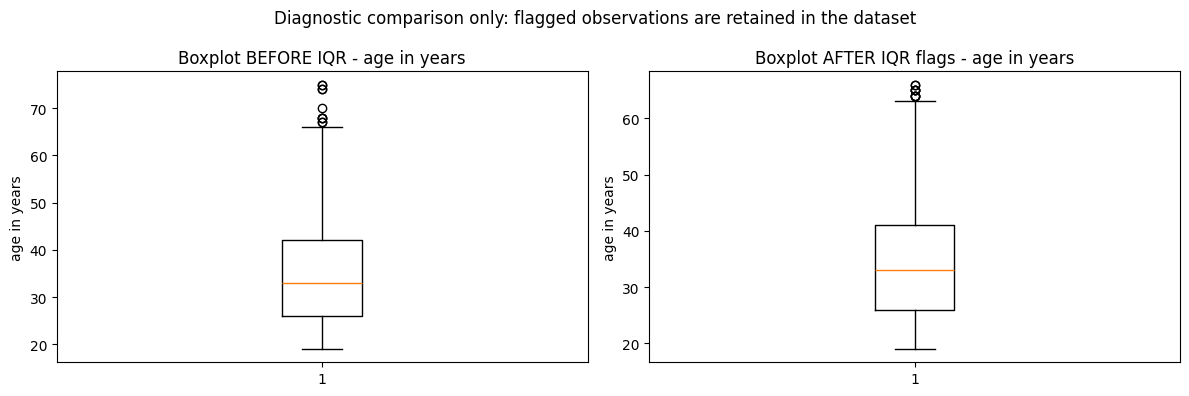

In [27]:
def iqr_outlier_report(training_frame, columns):
    rows = []
    for column in columns:
        q1, q3 = training_frame[column].quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        flagged = (training_frame[column] < lower) | (training_frame[column] > upper)
        rows.append({
            'english_column': feature_dictionary[column],
            'method': 'IQR (1.5 x IQR)',
            'lower_bound': lower,
            'upper_bound': upper,
            'flagged_count': int(flagged.sum()),
            'action': 'inspect; do not delete automatically',
        })
    return pd.DataFrame(rows)

def z_score_outlier_report(training_frame, columns, threshold=3.0):
    rows = []
    for column in columns:
        mean = training_frame[column].mean()
        std = training_frame[column].std(ddof=0)
        z_scores = (training_frame[column] - mean) / std if std else pd.Series(0.0, index=training_frame.index)
        flagged = z_scores.abs() > threshold
        rows.append({
            'english_column': feature_dictionary[column],
            'method': f'Z-score (|z| > {threshold:g})',
            'mean': mean,
            'std': std,
            'flagged_count': int(flagged.sum()),
            'action': 'inspect; do not delete automatically',
        })
    return pd.DataFrame(rows)

iqr_report = iqr_outlier_report(X_train, NUMERIC_COLUMNS)
z_score_report = z_score_outlier_report(X_train, NUMERIC_COLUMNS)
display(iqr_report)
display(z_score_report)

flagged_values_rows = []
for column in NUMERIC_COLUMNS:
    q1, q3 = X_train[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    iqr_lower, iqr_upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_mask = (X_train[column] < iqr_lower) | (X_train[column] > iqr_upper)
    mean = X_train[column].mean()
    std = X_train[column].std(ddof=0)
    z_lower, z_upper = mean - 3 * std, mean + 3 * std
    z_scores = (X_train[column] - mean) / std if std else pd.Series(0.0, index=X_train.index)
    z_mask = z_scores.abs() > 3
    for row_id in X_train.index[iqr_mask | z_mask]:
        methods = []
        if bool(iqr_mask.loc[row_id]):
            methods.append('IQR')
        if bool(z_mask.loc[row_id]):
            methods.append('z-score')
        flagged_values_rows.append({
            'row_id': row_id,
            'english_column': feature_dictionary[column],
            'value': X_train.loc[row_id, column],
            'reference_range': (
                f'IQR: {float(iqr_lower):g} to {float(iqr_upper):g}; '
                f'z-score: {float(z_lower):g} to {float(z_upper):g}'
            ),
            'method': ' + '.join(methods),
            'iqr_flagged': bool(iqr_mask.loc[row_id]),
            'z_score_flagged': bool(z_mask.loc[row_id]),
            'review_decision': 'valid-looking extreme; retained',
        })

flagged_values = pd.DataFrame(flagged_values_rows).sort_values(
    ['english_column', 'row_id']
).reset_index(drop=True)
flagged_values_path = ROOT / 'Mark' / 'Reference' / 'SouthGermanCredit_flagged_values.csv'
flagged_values_excel_path = ROOT / 'Mark' / 'Reference' / 'SouthGermanCredit_flagged_values.xlsx'
flagged_values_path.parent.mkdir(parents=True, exist_ok=True)
flagged_values.to_csv(flagged_values_path, index=False)
flagged_values.to_excel(flagged_values_excel_path, index=False, sheet_name='all_flags')
iqr_reference_sample = flagged_values.loc[flagged_values['iqr_flagged']].head(7)
print(f'All flagged training values saved to the reference files: {len(flagged_values)} rows')
print(f'Full Excel reference table: {flagged_values_excel_path}')
print('IQR reference sample: first 7 rows')
with pd.option_context('display.max_rows', 7, 'display.max_columns', None, 'display.width', 240):
    display(iqr_reference_sample)

def domain_error_counts(dataset):
    return {
        'loan duration <= 0': int((dataset['laufzeit'] <= 0).sum()),
        'credit amount <= 0': int((dataset['hoehe'] <= 0).sum()),
        'age <= 0': int((dataset['alter'] <= 0).sum()),
    }

domain_errors = pd.DataFrame([
    {'split': name, **domain_error_counts(dataset)}
    for name, dataset in [('full raw data', X_clean), ('training', X_train), ('test', X_test)]
])
display(domain_errors)
assert domain_errors.iloc[:, 1:].to_numpy().sum() == 0
print('Decision: retain valid extreme values; no outliers are removed automatically.')
# Course-style boxplot representation, adapted for leakage-safe review.
def _outlier_mask(training_frame, column, method='iqr', z_threshold=3.0):
    values = training_frame[column]
    method = method.lower()
    if method == 'iqr':
        q1, q3 = values.quantile([0.25, 0.75])
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
        return (values < lower_bound) | (values > upper_bound)
    if method == 'zscore':
        mean = values.mean()
        std = values.std(ddof=0)
        if std == 0:
            return pd.Series(False, index=values.index)
        return (((values - mean) / std).abs() > z_threshold)
    raise ValueError("method must be 'iqr' or 'zscore'")

def plot_outlier_boxplots(training_frame, columns, method='iqr', z_threshold=3.0):
    method_label = 'IQR' if method.lower() == 'iqr' else 'Z-score'
    for column in columns:
        values = training_frame[column].dropna()
        flags = _outlier_mask(training_frame, column, method, z_threshold).loc[values.index]
        retained_values = values.loc[~flags]
        english_name = feature_dictionary[column]

        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        axes[0].boxplot(values)
        axes[0].set_title(f'Boxplot BEFORE {method_label} - {english_name}')
        axes[0].set_ylabel(english_name)
        axes[1].boxplot(retained_values)
        axes[1].set_title(f'Boxplot AFTER {method_label} flags - {english_name}')
        axes[1].set_ylabel(english_name)
        fig.suptitle('Diagnostic comparison only: flagged observations are retained in the dataset')
        plt.tight_layout()
        plt.show()

OUTLIER_METHOD = 'iqr'
SHOW_OUTLIER_PLOTS = True
if SHOW_OUTLIER_PLOTS:
    plot_outlier_boxplots(X_train, NUMERIC_COLUMNS, method=OUTLIER_METHOD)

We visualise the data of the three numerical columns highlighted previously; loan duration in months, credit amount and age in years. All three plots show skewed distribution so applying IQR is superior to Z-score-based visualisation. This is because Z score calculates based on standard deviation and centers around 0, whereas the IQR adapts to data more spread out.

IQR flags values outside Q1 - 1.5 x IQR and Q3 + 1.5 x IQR; the z-score method flags values more than three standard deviations from the training mean. A flag means unusual, not wrong. A very large loan may be a real risk signal, so we inspect first and remove only a proven data error.

The decision is to keep the extreme values because they are valid and may carry risk information. We do not remove them based on model performance alone. A 72-year-old having a credit line is uncommon, but it is not automatically a data error. The complete list can be found under;

C:\Users\katom\iCloudDrive\Smaller Creator\Sky\Marc Torrens Assignment\Mark\Reference

---

#### 6. Encoding

In [28]:
from src.preprocessing import make_preprocessor

# Increment this version whenever a preprocessing edit creates a new dataset.
DATA_VERSION = 'onehot_v1'
preprocessor_demo = make_preprocessor()
X_train_transformed = preprocessor_demo.fit_transform(X_train)
X_test_transformed = preprocessor_demo.transform(X_test)

encoded_feature_names = preprocessor_demo.get_feature_names_out()

def transformed_frame(matrix, feature_names, index, target):
    values = matrix.toarray() if hasattr(matrix, 'toarray') else matrix
    output = pd.DataFrame(values, columns=feature_names, index=index)
    output.insert(0, 'row_id', output.index)
    output['bad_default_risk'] = target.to_numpy()
    return output.reset_index(drop=True)

encoded_train = transformed_frame(X_train_transformed, encoded_feature_names, X_train.index, y_train)
encoded_test = transformed_frame(X_test_transformed, encoded_feature_names, X_test.index, y_test)

processed_dir = ROOT / 'data' / 'processed'
processed_dir.mkdir(parents=True, exist_ok=True)
train_path = processed_dir / f'train_{DATA_VERSION}.csv'
test_path = processed_dir / f'test_{DATA_VERSION}.csv'
feature_map_path = processed_dir / f'feature_map_{DATA_VERSION}.csv'
manifest_path = processed_dir / f'manifest_{DATA_VERSION}.json'

encoded_train.to_csv(train_path, index=False)
encoded_test.to_csv(test_path, index=False)

def english_feature_name(model_feature):
    raw_name = model_feature.split('__', 1)[-1]
    if raw_name in feature_dictionary:
        return feature_dictionary[raw_name]
    for source_column in CATEGORICAL_COLUMNS:
        prefix = f'{source_column}_'
        if raw_name.startswith(prefix):
            return f'{feature_dictionary[source_column]} = {raw_name[len(prefix):]}'
    return raw_name

feature_map = pd.DataFrame({
    'model_feature': encoded_feature_names,
    'english_feature': [english_feature_name(name) for name in encoded_feature_names],
})
feature_map.to_csv(feature_map_path, index=False)

manifest = {
    'version': DATA_VERSION,
    'encoding': 'one-hot for all categorical predictors',
    'scaling': 'StandardScaler for loan duration, credit amount, and age',
    'fit_rule': 'fit_transform(training), then transform(test)',
    'random_state': RANDOM_STATE,
    'training_rows': int(len(encoded_train)),
    'test_rows': int(len(encoded_test)),
    'feature_count': int(len(encoded_feature_names)),
    'target': 'bad_default_risk',
    'train_dataset': str(train_path),
    'test_dataset': str(test_path),
    'feature_map': str(feature_map_path),
}
manifest_path.write_text(json.dumps(manifest, indent=2), encoding='utf-8')

print('Transformed training shape:', X_train_transformed.shape)
print('Transformed test shape:', X_test_transformed.shape)
print(f'Saved versioned training dataset: {train_path}')
print(f'Saved versioned test dataset: {test_path}')
print(f'Saved feature map: {feature_map_path}')
print(f'Saved manifest: {manifest_path}')
print('Correct: fit_transform(training), then transform(test).')

Transformed training shape: (800, 71)
Transformed test shape: (200, 71)
Saved versioned training dataset: c:\Users\katom\iCloudDrive\Smaller Creator\Sky\Marc Torrens Assignment\data\processed\train_onehot_v1.csv
Saved versioned test dataset: c:\Users\katom\iCloudDrive\Smaller Creator\Sky\Marc Torrens Assignment\data\processed\test_onehot_v1.csv
Saved feature map: c:\Users\katom\iCloudDrive\Smaller Creator\Sky\Marc Torrens Assignment\data\processed\feature_map_onehot_v1.csv
Saved manifest: c:\Users\katom\iCloudDrive\Smaller Creator\Sky\Marc Torrens Assignment\data\processed\manifest_onehot_v1.json
Correct: fit_transform(training), then transform(test).


In [29]:
contradiction_report = pd.DataFrame({
    'check': ['loan duration <= 0', 'credit amount <= 0', 'age <= 0', 'zero-information predictors'],
    'training_violations': [
        int((X_train['laufzeit'] <= 0).sum()),
        int((X_train['hoehe'] <= 0).sum()),
        int((X_train['alter'] <= 0).sum()),
        int(sum(X_train[c].nunique() <= 1 for c in X_train.columns)),
    ]
})
display(contradiction_report)

allowed_codes = {
    'laufkont': set(range(1, 5)), 'moral': set(range(0, 5)), 'verw': set(range(0, 11)),
    'sparkont': set(range(1, 6)), 'beszeit': set(range(1, 6)), 'rate': set(range(1, 5)),
    'famges': set(range(1, 5)), 'buerge': set(range(1, 4)), 'wohnzeit': set(range(1, 5)),
    'verm': set(range(1, 5)), 'weitkred': set(range(1, 4)), 'wohn': set(range(1, 4)),
    'bishkred': set(range(1, 5)), 'beruf': set(range(1, 5)), 'pers': set(range(1, 3)),
    'telef': set(range(1, 3)), 'gastarb': set(range(1, 3))
}
code_report = pd.DataFrame([
    {'english_column': feature_dictionary[column], 'invalid_codes': sorted(set(frame[column].unique()) - allowed)}
    for column, allowed in allowed_codes.items()
])
display(code_report)
assert all(len(values) == 0 for values in code_report['invalid_codes'])
print('Numeric predictors:', [feature_dictionary[c] for c in NUMERIC_COLUMNS])
print('Categorical predictors:', [feature_dictionary[c] for c in CATEGORICAL_COLUMNS])

,check,training_violations
0,loan duration <= 0,0
1,credit amount <= 0,0
2,age <= 0,0
3,zero-information predictors,0


,english_column,invalid_codes
0,existing checking-account status,[]
1,credit history,[]
2,loan purpose,[]
3,savings account or bonds,[]
4,employment duration,[]
5,installment rate as percentage of disposable i...,[]
6,personal status and sex code,[]
7,other debtors or guarantors,[]
8,years at present residence,[]
9,property status,[]


Numeric predictors: ['loan duration in months', 'credit amount', 'age in years']
Categorical predictors: ['existing checking-account status', 'credit history', 'loan purpose', 'savings account or bonds', 'employment duration', 'installment rate as percentage of disposable income', 'personal status and sex code', 'other debtors or guarantors', 'years at present residence', 'property status', 'other installment plans', 'housing status', 'number of existing credits at this bank', 'job category', 'number of people financially liable for', 'telephone status', 'foreign-worker code']


OneHotEncoder was applied to the categorical predictor columns. The three numeric predictors are separately imputed and scaled; categorical codes are treated as nominal in this pipeline.

---

#### 7. Fit and train each model

In [30]:
from src.models import make_candidate_models

models = make_candidate_models(random_state=RANDOM_STATE)
fitted_models = {}
for name, model in models.items():
    fitted_models[name] = model.fit(X_train, y_train)
print('Fitted models:', list(fitted_models))

Fitted models: ['majority_baseline', 'logistic_regression', 'decision_tree', 'random_forest']


`majority_baseline` — not a sophisticated model; it tells us whether the real models beat a trivial strategy.

`logistic_regression` — the main linear classification baseline.

`decision_tree` — interpretable nonlinear model.

`random_forest` — stronger ensemble comparison.

---

#### 8. Predict on test data and evaluate

In [31]:
policy_manifest = json.loads((ROOT / 'artifacts' / 'manifests' / 'wave-4-policy.json').read_text(encoding='utf-8'))
selected_model_name = policy_manifest['selected_model']
if selected_model_name not in fitted_models:
    raise KeyError(f'Selected model {selected_model_name!r} was not fitted. Available models: {list(fitted_models)}')
selected_fitted_model = fitted_models[selected_model_name]
test_predictions = {selected_model_name: selected_fitted_model.predict(X_test)}
test_risk_scores = {selected_model_name: selected_fitted_model.predict_proba(X_test)[:, 1]}

prediction_preview = pd.DataFrame({
    'actual_outcome': y_test.map({0: 'good/performing', 1: 'bad/default-risk'}).to_numpy(),
    'actual_bad_default_risk': y_test.to_numpy(),
    'predicted_bad_default_risk_probability': test_risk_scores[selected_model_name],
    'predicted_outcome_at_0.50': np.where(test_predictions[selected_model_name] == 1, 'bad/default-risk', 'good/performing'),
}, index=X_test.index).head(10)
display(prediction_preview)
print(f'Prediction completed with selected model: {selected_model_name}')

,actual_outcome,actual_bad_default_risk,predicted_bad_default_risk_probability,predicted_outcome_at_0.50
233,good/performing,0,0.438571,good/performing
883,bad/default-risk,1,0.479193,good/performing
316,good/performing,0,0.266698,good/performing
297,good/performing,0,0.084803,good/performing
681,good/performing,0,0.153475,good/performing
540,bad/default-risk,1,0.346093,good/performing
760,bad/default-risk,1,0.305506,good/performing
489,good/performing,0,0.177605,good/performing
122,good/performing,0,0.345790,good/performing
614,good/performing,0,0.495291,good/performing


Prediction completed with selected model: random_forest


In [32]:
import hashlib
from src.evaluation import binary_metrics
from src.threshold_policy import metrics_at_capacity, BUSINESS_ASSUMPTIONS

oof = pd.read_csv(ROOT / 'artifacts' / 'tables' / 'wave-4-oof-threshold-table-all-models.csv')
oof_capacity = oof[oof['policy'].eq('recommended_capacity_constrained')].sort_values('net_screening_value', ascending=False)
display(oof_capacity[['model', 'accuracy', 'precision', 'recall', 'f1', 'monthly_reviews', 'net_screening_value']])

policy_manifest = json.loads((ROOT / 'artifacts' / 'manifests' / 'wave-4-policy.json').read_text(encoding='utf-8'))
run_manifest = json.loads((ROOT / 'artifacts' / 'manifests' / 'waves-0-3-run.json').read_text(encoding='utf-8'))
raw_hash = hashlib.sha256(RAW_PATH.read_bytes()).hexdigest()
assert run_manifest['raw_source']['sha256'] == raw_hash
assert run_manifest['random_state'] == RANDOM_STATE
selected_model_name = policy_manifest['selected_model']
assert selected_model_name == oof_capacity.iloc[0]['model']
print('Selected by development OOF business value:', selected_model_name)
print('Business assumptions:', BUSINESS_ASSUMPTIONS)

,model,accuracy,precision,recall,f1,monthly_reviews,net_screening_value
23,random_forest,0.7600,0.65000,0.433333,0.520,1600.0,2718400.0
11,logistic_regression,0.7550,0.63750,0.425000,0.510,1600.0,2663200.0
17,decision_tree,0.6925,0.48125,0.320833,0.385,1600.0,1973200.0
5,majority_baseline,0.6375,0.34375,0.229167,0.275,1600.0,1366000.0


Selected by development OOF business value: random_forest
Business assumptions: {'monthly_applications': 8000, 'max_monthly_reviews': 1600, 'review_cost': 35.0, 'lgd': 6000.0, 'review_effectiveness': 0.45, 'performing_contribution': 1200.0, 'abandonment_rate': 0.05}


The selected model for this notebook version is **Random Forest**, chosen from development out-of-fold capacity-constrained net screening value. The frozen test is not used to choose the model or policy.


In [33]:
selected_score = test_risk_scores[selected_model_name]
selected_default = binary_metrics(y_test, selected_score, threshold=0.50)
selected_top20 = metrics_at_capacity(
    y_test, selected_score,
    BUSINESS_ASSUMPTIONS['max_monthly_reviews'] / BUSINESS_ASSUMPTIONS['monthly_applications']
)
selected_metrics = pd.DataFrame([
    {'policy': 'threshold = 0.50', **{key: selected_default[key] for key in ['accuracy', 'balanced_accuracy', 'precision', 'recall', 'specificity', 'f1', 'roc_auc', 'average_precision', 'brier']}},
    {'policy': 'ranked top 20%', **{key: selected_top20[key] for key in ['accuracy', 'precision', 'recall', 'f1']}, 'specificity': selected_top20['tn'] / (selected_top20['tn'] + selected_top20['fp']), 'balanced_accuracy': None, 'roc_auc': None, 'average_precision': None, 'brier': None}
])
display(selected_metrics)
display(pd.DataFrame([selected_top20])[['tn', 'fp', 'fn', 'tp', 'monthly_reviews', 'net_screening_value', 'cost_per_expected_default_prevented']])
print('TP = bad-risk cases sent to review; FN = bad-risk cases missed by the queue.')

,policy,accuracy,balanced_accuracy,precision,recall,specificity,f1,roc_auc,average_precision,brier
0,threshold = 0.50,0.74,0.604762,0.666667,0.266667,0.942857,0.380952,0.767143,0.587343,0.173413
1,ranked top 20%,0.74,NaN,0.600000,0.400000,0.885714,0.480000,NaN,NaN,NaN


,tn,fp,fn,tp,monthly_reviews,net_screening_value,cost_per_expected_default_prevented
0,124,16,36,24,1600.0,2497600.0,129.62963


TP = bad-risk cases sent to review; FN = bad-risk cases missed by the queue.


,not selected for enhanced review,selected for enhanced review
actual good/performing,124,16
actual bad/default-risk,36,24


Rows are actual classes; columns are the review decision.
TN = good cases not selected; FP = good cases selected; FN = bad-risk cases missed; TP = bad-risk cases selected.


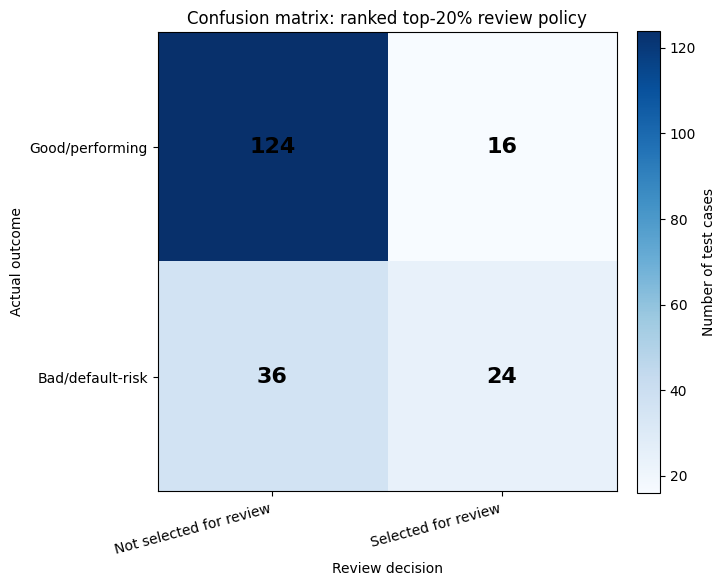

In [34]:
confusion_matrix_table = pd.DataFrame(
    [
        [selected_top20['tn'], selected_top20['fp']],
        [selected_top20['fn'], selected_top20['tp']],
    ],
    index=['actual good/performing', 'actual bad/default-risk'],
    columns=['not selected for enhanced review', 'selected for enhanced review'],
)
display(confusion_matrix_table)
print('Rows are actual classes; columns are the review decision.')
print('TN = good cases not selected; FP = good cases selected; FN = bad-risk cases missed; TP = bad-risk cases selected.')

confusion_values = confusion_matrix_table.to_numpy(dtype=int)
fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(confusion_values, cmap='Blues')
ax.set_xticks(range(2))
ax.set_xticklabels(['Not selected for review', 'Selected for review'], rotation=15, ha='right')
ax.set_yticks(range(2))
ax.set_yticklabels(['Good/performing', 'Bad/default-risk'])
ax.set_xlabel('Review decision')
ax.set_ylabel('Actual outcome')
ax.set_title('Confusion matrix: ranked top-20% review policy')
for row in range(confusion_values.shape[0]):
    for column in range(confusion_values.shape[1]):
        ax.text(column, row, confusion_values[row, column], ha='center', va='center', color='black', fontsize=16, fontweight='bold')
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04, label='Number of test cases')
plt.tight_layout()
plt.show()

<div style="border: 1px solid #5b8db8; border-radius: 8px; padding: 16px; margin: 8px 0; background-color: rgba(91, 141, 184, 0.08);">

<h4>Ideal model; random-forest.</h4>
<p><strong>Most important metrics;</strong></p>
<table style="width: 100%; border-collapse: collapse;">
<tr><th style="text-align: left; padding: 6px; border-bottom: 1px solid #5b8db8;"></th><th style="text-align: left; padding: 6px; border-bottom: 1px solid #5b8db8;">model</th><th style="text-align: left; padding: 6px; border-bottom: 1px solid #5b8db8;">accuracy</th><th style="text-align: left; padding: 6px; border-bottom: 1px solid #5b8db8;">precision</th><th style="text-align: left; padding: 6px; border-bottom: 1px solid #5b8db8;">recall</th><th style="text-align: left; padding: 6px; border-bottom: 1px solid #5b8db8;">f1</th><th style="text-align: left; padding: 6px; border-bottom: 1px solid #5b8db8;">monthly_reviews</th><th style="text-align: left; padding: 6px; border-bottom: 1px solid #5b8db8;">net_screening_value</th></tr>
<tr><td style="padding: 6px;">test</td><td style="padding: 6px;">random_forest</td><td style="padding: 6px;">0.7400</td><td style="padding: 6px;">0.6000</td><td style="padding: 6px;">0.4000</td><td style="padding: 6px;">0.4800</td><td style="padding: 6px;">1600.0</td><td style="padding: 6px;">2497600.0</td></tr>
</table>
<p>Accuracy = (TP + TN) / ALL = What % did the model get right of all predictions (0/1 = historical bad-risk / good-performing)</p>
<p>Precision = TP / (TP + FP) = What % of the historical bad-risk predictions the model made were correct?</p>
<p>Recall = TP / (TP + FN) = What % of historical bad-risk cases did we actually identify?</p>
<p>F1 = 2 x Precision x Recall / (Precision + Recall) = Benchmark combining Precision and Recall</p>

</div>

##### 8.1 Required threshold table and probability validation


,model,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,log_loss_mean,log_loss_std,brier_mean,brier_std,specificity_at_0.50_mean,specificity_at_0.50_std
3,random_forest,0.797210,0.036785,0.641748,0.081058,0.499079,2.018492e-02,0.164675,9.165911e-03,0.944643,0.026336
1,logistic_regression,0.780246,0.038358,0.611127,0.086227,0.514791,5.728971e-02,0.167811,1.904416e-02,0.869643,0.035490
2,decision_tree,0.692281,0.027637,0.454859,0.048227,0.934772,2.994050e-01,0.202060,1.560502e-02,0.775000,0.081929
0,majority_baseline,0.500000,0.000000,0.300000,0.000000,0.610864,1.241267e-16,0.210000,2.775558e-17,1.000000,0.000000


,mean_predicted_bad_risk,observed_bad_risk
0,0.095605,0.03750
1,0.188174,0.16875
2,0.282388,0.23750
3,0.393914,0.40625
4,0.544210,0.65000


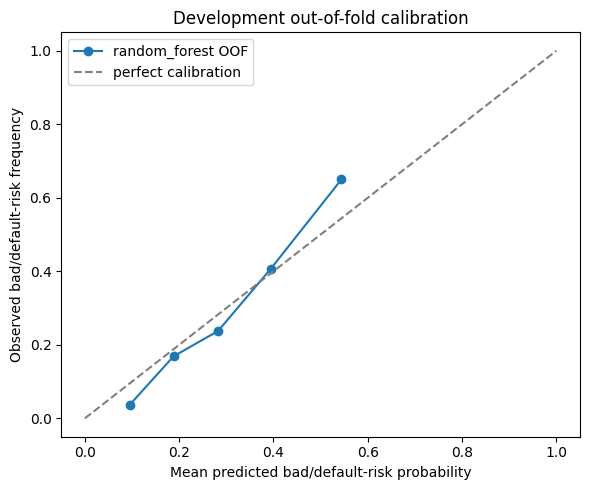

In [35]:
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.metrics import average_precision_score, brier_score_loss, confusion_matrix, log_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
selected_oof_scores = np.empty(len(y_train), dtype=float)
for name, estimator in models.items():
    fold_rows = []
    for fold, (fit_idx, validation_idx) in enumerate(cv.split(X_train, y_train), start=1):
        fold_model = clone(estimator)
        fold_model.fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
        validation_scores = fold_model.predict_proba(X_train.iloc[validation_idx])[:, 1]
        validation_labels = y_train.iloc[validation_idx]
        validation_predictions = (validation_scores >= 0.50).astype(int)
        tn, fp, fn, tp = confusion_matrix(validation_labels, validation_predictions, labels=[0, 1]).ravel()
        fold_rows.append({'roc_auc': roc_auc_score(validation_labels, validation_scores), 'average_precision': average_precision_score(validation_labels, validation_scores), 'log_loss': log_loss(validation_labels, np.column_stack([1 - validation_scores, validation_scores]), labels=[0, 1]), 'brier': brier_score_loss(validation_labels, validation_scores), 'specificity_at_0.50': tn / (tn + fp) if (tn + fp) else 0.0})
        if name == selected_model_name:
            selected_oof_scores[validation_idx] = validation_scores
    fold_frame = pd.DataFrame(fold_rows)
    summary = {'model': name}
    for metric in ['roc_auc', 'average_precision', 'log_loss', 'brier', 'specificity_at_0.50']:
        summary[f'{metric}_mean'] = fold_frame[metric].mean()
        summary[f'{metric}_std'] = fold_frame[metric].std(ddof=1)
    cv_rows.append(summary)
cv_probability_metrics = pd.DataFrame(cv_rows).sort_values('roc_auc_mean', ascending=False)
display(cv_probability_metrics)
calibration_fraction, calibration_mean = calibration_curve(y_train, selected_oof_scores, n_bins=5, strategy='quantile')
calibration_table = pd.DataFrame({'mean_predicted_bad_risk': calibration_mean, 'observed_bad_risk': calibration_fraction})
display(calibration_table)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(calibration_mean, calibration_fraction, marker='o', label=f'{selected_model_name} OOF')
ax.plot([0, 1], [0, 1], linestyle='--', color='grey', label='perfect calibration')
ax.set_xlabel('Mean predicted bad/default-risk probability')
ax.set_ylabel('Observed bad/default-risk frequency')
ax.set_title('Development out-of-fold calibration')
ax.legend()
plt.tight_layout()
plt.show()

##### 8.2 Frozen-test discrimination plots


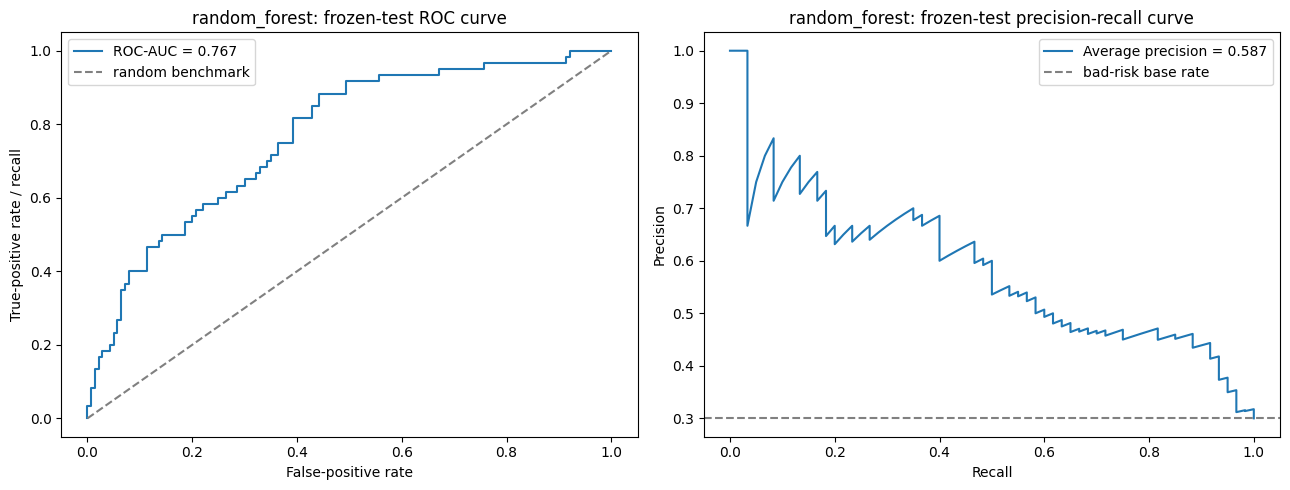

Frozen-test ROC-AUC: 0.7671
Frozen-test average precision: 0.5873


In [36]:
from sklearn.metrics import auc, precision_recall_curve, roc_curve

# These plots report discrimination on the frozen test set; they do not select the policy.
fpr, tpr, _ = roc_curve(y_test, selected_score)
precision_curve, recall_curve, _ = precision_recall_curve(y_test, selected_score)
roc_auc_test = auc(fpr, tpr)
average_precision_test = average_precision_score(y_test, selected_score)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(fpr, tpr, label=f'ROC-AUC = {roc_auc_test:.3f}')
axes[0].plot([0, 1], [0, 1], linestyle='--', color='grey', label='random benchmark')
axes[0].set_title(f'{selected_model_name}: frozen-test ROC curve')
axes[0].set_xlabel('False-positive rate')
axes[0].set_ylabel('True-positive rate / recall')
axes[0].legend()

axes[1].plot(recall_curve, precision_curve, label=f'Average precision = {average_precision_test:.3f}')
axes[1].axhline(y=float(y_test.mean()), linestyle='--', color='grey', label='bad-risk base rate')
axes[1].set_title(f'{selected_model_name}: frozen-test precision-recall curve')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend()

plt.tight_layout()
plt.show()
print(f'Frozen-test ROC-AUC: {roc_auc_test:.4f}')
print(f'Frozen-test average precision: {average_precision_test:.4f}')


The curves show that in general the more people are sent for review the more bad cases are captured (positive class), but beyond 0.4-0.5 the effectiveness decreases significantly. The model places bad-risk applicants near the top in a queue of high to low-risk applicants, and at our cutoff of 20% highest risk applications, 59% actually turns out to be a bad-risk (true positive) applicant.

##### 8.3 Six operating points and required threshold table


In [37]:
from src.threshold_policy import metrics_at_threshold

# Threshold candidates are fixed from development-only policy work. The frozen test is used only to confirm them.
manifest_points = policy_manifest['operating_points']
capacity_fraction = BUSINESS_ASSUMPTIONS['max_monthly_reviews'] / BUSINESS_ASSUMPTIONS['monthly_applications']
operating_point_specs = [
    ('default threshold 0.50', 'threshold', 0.50),
    (f"high recall threshold {float(manifest_points['high_recall']['threshold']):.2f}", 'threshold', float(manifest_points['high_recall']['threshold'])),
    ('additional mid-range threshold 0.40', 'threshold', 0.40),
    (f"high precision threshold {float(manifest_points['high_precision']['threshold']):.2f}", 'threshold', float(manifest_points['high_precision']['threshold'])),
    ('higher-precision low-volume threshold 0.65', 'threshold', 0.65),
    (f"capacity-constrained / recommended top 20% (reference threshold {float(manifest_points['capacity_top_20_percent']['threshold']):.2f})", 'top_k', capacity_fraction),
]

def table_row(split, label, selection_rule, metrics, sample_size):
    count_scale = BUSINESS_ASSUMPTIONS['monthly_applications'] / sample_size
    threshold_text = f"reference {metrics['threshold']:.4f}" if selection_rule == 'top_k' else f"threshold {metrics['threshold']:.2f}"
    return {
        'split': split,
        'model and threshold': f"{selected_model_name}; {label} ({threshold_text})",
        'selection rule': selection_rule,
        'reviews': int(round(metrics['monthly_reviews'])),
        'review %': f"{metrics['review_rate']:.1%}",
        'TP': int(round(metrics['tp'] * count_scale)),
        'FP': int(round(metrics['fp'] * count_scale)),
        'FN': int(round(metrics['fn'] * count_scale)),
        'TN': int(round(metrics['tn'] * count_scale)),
        'precision': metrics['precision'],
        'recall': metrics['recall'],
        'F1': metrics['f1'],
        'loss avoided': metrics['gross_loss_avoided'],
        'expected defaults prevented': metrics['expected_defaults_prevented'],
        'review cost': metrics['monthly_review_cost'],
        'lost contribution from friction': metrics['lost_contribution_from_friction'],
        'cost per expected default prevented': metrics['cost_per_expected_default_prevented'],
        'missed avoidable loss': metrics['missed_avoidable_loss'],
        'net value': metrics['net_screening_value'],
    }

def calculate_points(y_values, score_values):
    rows = []
    for label, rule, value in operating_point_specs:
        if rule == 'top_k':
            metrics = metrics_at_capacity(y_values, score_values, value, BUSINESS_ASSUMPTIONS)
        else:
            metrics = metrics_at_threshold(y_values, score_values, value, BUSINESS_ASSUMPTIONS)
        rows.append((label, rule, metrics))
    return rows

development_points = calculate_points(y_train, selected_oof_scores)
frozen_test_points = calculate_points(y_test, selected_score)

# The required table is the frozen-test confirmation, scaled from 200 rows to 8,000 applications.
required_threshold_table = pd.DataFrame([
    table_row('frozen test confirmation', label, rule, metrics, len(y_test))
    for (label, rule, metrics) in frozen_test_points
])
assert len(required_threshold_table) == 6

# Development values document selection without using frozen-test outcomes.
development_policy_table = pd.DataFrame([
    table_row('development OOF selection', label, rule, metrics, len(y_train))
    for (label, rule, metrics) in development_points
])

display(required_threshold_table)
display(development_policy_table[['model and threshold', 'reviews', 'precision', 'recall', 'net value']])
print('The recommended policy is the top-20% row.')


,split,model and threshold,selection rule,reviews,review %,TP,FP,FN,TN,precision,recall,F1,loss avoided,expected defaults prevented,review cost,lost contribution from friction,cost per expected default prevented,missed avoidable loss,net value
0,frozen test confirmation,random_forest; default threshold 0.50 (thresho...,threshold,960,12.0%,640,320,1760,5280,0.666667,0.266667,0.380952,1728000.0,288.0,33600.0,19200.0,116.666667,4752000.0,1675200.0
1,frozen test confirmation,random_forest; high recall threshold 0.29 (thr...,threshold,3160,39.5%,1520,1640,880,3960,0.481013,0.633333,0.546763,4104000.0,684.0,110600.0,98400.0,161.695906,2376000.0,3895000.0
2,frozen test confirmation,random_forest; additional mid-range threshold ...,threshold,1960,24.5%,1160,800,1240,4800,0.591837,0.483333,0.532110,3132000.0,522.0,68600.0,48000.0,131.417625,3348000.0,3015400.0
3,frozen test confirmation,random_forest; high precision threshold 0.58 (...,threshold,320,4.0%,240,80,2160,5520,0.750000,0.100000,0.176471,648000.0,108.0,11200.0,4800.0,103.703704,5832000.0,632000.0
4,frozen test confirmation,random_forest; higher-precision low-volume thr...,threshold,160,2.0%,120,40,2280,5560,0.750000,0.050000,0.093750,324000.0,54.0,5600.0,2400.0,103.703704,6156000.0,316000.0
5,frozen test confirmation,random_forest; capacity-constrained / recommen...,top_k,1600,20.0%,960,640,1440,4960,0.600000,0.400000,0.480000,2592000.0,432.0,56000.0,38400.0,129.629630,3888000.0,2497600.0


,model and threshold,reviews,precision,recall,net value
0,random_forest; default threshold 0.50 (thresho...,1090,0.715596,0.325000,2049250.0
1,random_forest; high recall threshold 0.29 (thr...,3860,0.497409,0.800000,4932500.0
2,random_forest; additional mid-range threshold ...,2340,0.589744,0.575000,3586500.0
3,random_forest; high precision threshold 0.58 (...,450,0.800000,0.150000,950850.0
4,random_forest; higher-precision low-volume thr...,130,1.000000,0.054167,346450.0
5,random_forest; capacity-constrained / recommen...,1600,0.650000,0.433333,2718400.0


The recommended policy is the top-20% row.


We compare different "cut-offs" but under our constraint of 1600 monthly reviews, the 20% cut-off is most optimal.

##### 8.3.1 Model comparison at the fixed review capacity


In [38]:
development_model_comparison = oof[oof['policy'].eq('recommended_capacity_constrained')].copy()
development_model_comparison['split'] = 'development OOF'
development_model_comparison['model and policy'] = development_model_comparison.apply(lambda row: f"{row['model']}; top 20% (reference {row['threshold']:.4f})", axis=1)
development_model_comparison['reviews'] = int(BUSINESS_ASSUMPTIONS['monthly_applications'] * 0.20)
development_scale = BUSINESS_ASSUMPTIONS['monthly_applications'] / len(y_train)
for count_column in ['tn', 'fp', 'fn', 'tp']:
    development_model_comparison[count_column.upper()] = (development_model_comparison[count_column] * development_scale).round().astype(int)
development_model_comparison['loss avoided'] = development_model_comparison['gross_loss_avoided']
development_model_comparison['net value'] = development_model_comparison['net_screening_value']
development_model_comparison = development_model_comparison[['split', 'model and policy', 'reviews', 'TP', 'FP', 'FN', 'TN', 'accuracy', 'precision', 'recall', 'f1', 'loss avoided', 'net value']]
test_scale = BUSINESS_ASSUMPTIONS['monthly_applications'] / len(y_test)
frozen_test_model_row = pd.DataFrame([{'split': 'frozen test confirmation', 'model and policy': f"{selected_model_name}; top 20% (reference {selected_top20['threshold']:.4f})", 'reviews': int(round(selected_top20['monthly_reviews'])), 'TP': int(round(selected_top20['tp'] * test_scale)), 'FP': int(round(selected_top20['fp'] * test_scale)), 'FN': int(round(selected_top20['fn'] * test_scale)), 'TN': int(round(selected_top20['tn'] * test_scale)), 'accuracy': selected_top20['accuracy'], 'precision': selected_top20['precision'], 'recall': selected_top20['recall'], 'f1': selected_top20['f1'], 'loss avoided': selected_top20['gross_loss_avoided'], 'net value': selected_top20['net_screening_value']}])
model_comparison_table = pd.concat([development_model_comparison, frozen_test_model_row], ignore_index=True)
display(model_comparison_table)


,split,model and policy,reviews,TP,FP,FN,TN,accuracy,precision,recall,f1,loss avoided,net value
0,development OOF,majority_baseline; top 20% (reference 0.3000),1600,550,1050,1850,4550,0.6375,0.34375,0.229167,0.275,1485000.0,1366000.0
1,development OOF,logistic_regression; top 20% (reference 0.5607),1600,1020,580,1380,5020,0.7550,0.63750,0.425000,0.510,2754000.0,2663200.0
2,development OOF,decision_tree; top 20% (reference 0.5333),1600,770,830,1630,4770,0.6925,0.48125,0.320833,0.385,2079000.0,1973200.0
3,development OOF,random_forest; top 20% (reference 0.4511),1600,1040,560,1360,5040,0.7600,0.65000,0.433333,0.520,2808000.0,2718400.0
4,frozen test confirmation,random_forest; top 20% (reference 0.4340),1600,960,640,1440,4960,0.7400,0.60000,0.400000,0.480,2592000.0,2497600.0


`Net value = Loss avoided − review cost − opportunity cost`

**Loss avoided** = `TP × 45% review effectiveness × EUR 6,000 LGD`

**Review cost** = `all reviews × EUR 35`

**Opportunity Cost** = `FP × 5% abandonment × EUR 1,200 contribution`

This test also confirms random forest is the most ideal since the net value is highest.

##### Interpretation

### What changes if recall rises while precision falls?

Recall is how many of the positive classes we capture. In my opinion the most important metric.
Precision is out of all the positive class predictions (sent for human review) how many were actually in the positive class (were actually needed to be sent).

Higher recall while lower precision means we likely send more people for human review - and as such we are capturing more of the positive class but at higher cost.

### Which error is more expensive?

- One false negative = expected loss of 45% x EUR 6,000 = EUR 2,700.
- One false positive = expected loss of 5% x EUR 1,200 = EUR 60.

Therefore a false negative is potentially **45 times more expensive** than a false positive in the scenario. This alone is not definitive, but enough to priortise minimising false negatives.

### Why does prevalence matter?

Because that is what all our metrics depend on.
Prevalence = how many positive classes we have in the dataset > how many bad-risk cases.
In our case, 30%, if that was higher, our models should capture more of them since they are more "prevailent". And vice versa.

### Which policy should be used?

Rank bad-risk value (0-1) in descending order, send the top 20% for human review.
As they will be the highest risk for default, we should focus on them given our limited capacity.

### What information is missing?

- Did the default occur at any of them?
- Was the loan actually given? For how long?
- Do all defaults create the same loss? Unlikely.
- Economic conditions may also be useful > recession = higher defaults = higher risk
- A lot more data than 1000 rows.

##### 8.4 Sensitivity analysis


In [39]:
sensitivity_test = pd.read_csv(ROOT / 'artifacts' / 'tables' / 'wave-5-sensitivity-test.csv')
sensitivity_table = sensitivity_test.rename(columns={
    'review_effectiveness': 'review effectiveness',
    'lgd': 'loss given default',
    'review_cost': 'review cost',
    'abandonment_rate': 'abandonment rate',
    'net_screening_value': 'net value',
    'expected_defaults_prevented': 'expected defaults prevented',
})[[
    'scenario', 'review effectiveness', 'loss given default', 'review cost',
    'abandonment rate', 'expected defaults prevented', 'net value',
]]
display(sensitivity_table)
assert {'base', 'conservative', 'adverse', 'upside'}.issubset(set(sensitivity_table['scenario']))
print('The recommendation remains positive in all four conditional scenarios; real-world profitability still requires observed outcomes and measured review effectiveness.')


,scenario,review effectiveness,loss given default,review cost,abandonment rate,expected defaults prevented,net value
0,base,0.45,6000.0,35.0,0.05,432.0,2497600.0
1,conservative,0.30,4000.0,45.0,0.08,288.0,1018560.0
2,adverse,0.20,3000.0,60.0,0.10,192.0,403200.0
3,upside,0.60,8000.0,25.0,0.03,576.0,4544960.0


The recommendation remains positive in all four conditional scenarios; real-world profitability still requires observed outcomes and measured review effectiveness.


With the worst case scenario of 0.20 review effectiveness, our net value is proojected to be 403200.0, still relatively good, as such the recommendations stay the same.

##### 8.5 Governance and subgroup audit


In [ ]:
subgroup_audit = pd.read_csv(ROOT / 'artifacts' / 'tables' / 'wave-9-subgroup-audit.csv')
display(subgroup_audit)
print('This is an audit-only diagnostic. It was not used for model or threshold selection.')


,feature,group,n,positive_bad_risk,selected_for_review,selection_rate,selection_rate_ci_low,selection_rate_ci_high,precision,recall_tpr,fpr
0,famges,1,11,3,3,0.272727,0.060218,0.609743,0.333333,0.333333,0.250000
1,famges,2,53,19,14,0.264151,0.152568,0.403279,0.571429,0.421053,0.176471
2,famges,3,120,32,18,0.150000,0.091390,0.226667,0.611111,0.343750,0.079545
3,famges,4,16,6,5,0.312500,0.110170,0.586621,0.800000,0.666667,0.100000
4,gastarb,1,8,1,3,0.375000,0.085233,0.755137,0.333333,1.000000,0.285714
5,gastarb,2,192,59,37,0.192708,0.139463,0.255700,0.621622,0.389831,0.105263


This is an audit-only diagnostic. It was not used for model or threshold selection.


The audit checks selection rate, precision, recall/TPR and FPR for `famges` and `gastarb`, groups for differences in sex and foreign-worker status. There is no signficant difference between risk-ranking, but several groups are too small to draw a definite conclusion - gastarb 1 = 8 members.

##### 8.6 Reproducibility note


In [ ]:
import importlib.metadata as package_metadata
import platform

packages = ['numpy', 'pandas', 'matplotlib', 'scikit-learn', 'nbformat', 'openpyxl', 'joblib']
version_rows = []
for package in packages:
    try:
        version = package_metadata.version(package)
    except package_metadata.PackageNotFoundError:
        version = 'not installed'
    version_rows.append({'package': package, 'version': version})

display(pd.DataFrame(version_rows))
print('Python:', platform.python_version())
print('Random seed:', RANDOM_STATE)
print('Project root is discovered from the current working directory and its parents; data and artifacts are referenced with relative project paths.')
print('Run from the project root: jupyter nbconvert --to notebook --execute notebooks/main.v5.ipynb --output notebooks/main.v5.executed.ipynb')


,package,version
0,numpy,2.4.1
1,pandas,2.3.3
2,matplotlib,3.10.8
3,scikit-learn,1.8.0
4,nbformat,5.11.1


Python: 3.14.2
Random seed: 77
Project root is discovered from the notebook location; data and artifacts are referenced with relative project paths.
Run from the project root: jupyter nbconvert --to notebook --execute notebooks/main.v5.ipynb --output notebooks/main.v5.executed.ipynb


Notes from AI;

The notebook uses a fixed random seed, leakage-safe pipelines, development cross-validation/OOF predictions for model and policy selection, and one frozen-test confirmation for final reporting. The `good/bad` label is a historical proxy; it is not an observed 12-month default outcome, so rollout requires monitoring, calibration and validation against real 12-month outcomes before deployment.


The selected Random Forest is evaluated at the exact top-20% ranking policy. The development row is used for policy selection; the frozen-test row is a confirmation only. The displayed threshold is a reference boundary for the current sample, while the operating rule remains exact top-k ranking.



<div style="border: 1px solid #5b8db8; border-radius: 8px; padding: 16px; margin: 16px 0; background-color: rgba(91, 141, 184, 0.08);">
<h4>Scaled to 8,000 monthly applications</h4>
<p>The 200 frozen-test applicants are scaled by 40 to represent 8,000 monthly applications. The 20% review capacity therefore sends 1,600 applicants to human review.</p>
<table style="width: 100%; border-collapse: collapse;">
<tr><th style="text-align: left; padding: 6px; border-bottom: 1px solid #5b8db8;">Measure</th><th style="text-align: left; padding: 6px; border-bottom: 1px solid #5b8db8;">Scaled result</th><th style="text-align: left; padding: 6px; border-bottom: 1px solid #5b8db8;">Calculation / meaning</th></tr>
<tr><td style="padding: 6px;">Model and selection rule</td><td style="padding: 6px;">Random forest; top 20%</td><td style="padding: 6px;">Ranked risk scores; exactly the highest-scoring 20% are sent to human review</td></tr>
<tr><td style="padding: 6px;">True negatives (TN)</td><td style="padding: 6px;">4,960</td><td style="padding: 6px;">124 x 40; good applicants not selected</td></tr>
<tr><td style="padding: 6px;">False positives (FP)</td><td style="padding: 6px;">640</td><td style="padding: 6px;">16 x 40; good applicants selected</td></tr>
<tr><td style="padding: 6px;">False negatives (FN)</td><td style="padding: 6px;">1,440</td><td style="padding: 6px;">36 x 40; bad-risk applicants missed</td></tr>
<tr><td style="padding: 6px;">True positives (TP)</td><td style="padding: 6px;">960</td><td style="padding: 6px;">24 x 40; bad-risk applicants selected</td></tr>
<tr><td style="padding: 6px;">Human reviews</td><td style="padding: 6px;">1,600</td><td style="padding: 6px;">640 FP + 960 TP = 20% of 8,000</td></tr>
<tr><td style="padding: 6px;">Precision</td><td style="padding: 6px;">60%</td><td style="padding: 6px;">960 / (960 + 640)</td></tr>
<tr><td style="padding: 6px;">Recall</td><td style="padding: 6px;">40%</td><td style="padding: 6px;">960 / (960 + 1,440)</td></tr>
<tr><td style="padding: 6px;">Accuracy</td><td style="padding: 6px;">74%</td><td style="padding: 6px;">(4,960 + 960) / 8,000</td></tr>
<tr><td style="padding: 6px;">Loss avoided</td><td style="padding: 6px;">EUR 2,592,000</td><td style="padding: 6px;">960 TP x 45% effectiveness x EUR 6,000 loss given default</td></tr>
<tr><td style="padding: 6px;">Human-review cost</td><td style="padding: 6px;">EUR 56,000</td><td style="padding: 6px;">1,600 reviews x EUR 35</td></tr>
<tr><td style="padding: 6px;">Expected contribution lost</td><td style="padding: 6px;">EUR 38,400</td><td style="padding: 6px;">640 FP x 5% abandonment x EUR 1,200 contribution</td></tr>
<tr><td style="padding: 6px;"><strong>Net expected screening value</strong></td><td style="padding: 6px;"><strong>EUR 2,497,600</strong></td><td style="padding: 6px;">EUR 2,592,000 - EUR 56,000 - EUR 38,400</td></tr>
</table>
<p><strong>Interpretation:</strong> this is incremental net screening value from the enhanced-review queue, not the total contribution of all performing applicants.</p>
<p><strong>Scaling note:</strong> this is an extrapolation from the 200-row frozen test set. It assumes that the test-set rates remain representative of 8,000 future monthly applications. The same 40:1 application-to-test-set scaling is used.</p>
</div>

<div style="border: 1px solid #5b8db8; border-radius: 8px; padding: 16px; margin: 16px 0; background-color: rgba(91, 141, 184, 0.08);">
<h4>Current Conclusion scaled to 8,000 monthly applications</h4>
<p>€2,497,600 scenario net screening value per month for 1,600 applicants selected for human review.</p>
<p>Since maximum human review per month = 1,600, which is 20% of 8,000, we send the top 20% highest-risk applications for human review.</p>
<p>The 1,600 reviewed applicants consist of 960 TP and 640 FP.</p>
<p>60% precision means 960/1,600 times when the model marked someone for human review, that person was historical bad-risk.</p>
<p>That means scenario net expected value = (960 × 45% × €6,000) - (model-running cost, assumed negligible and not quantified here + 1,600 × €35 for human review + 640 × 5% × €1,200 for clients lost through unnecessary review) = €2,592,000 - €56,000 - €38,400 = €2,497,600 per month at 8,000 applications.</p>
<p>A recall of 40% means out of all historical bad-risk cases we are capturing 40%, approximately 6 out of every 15 people. As such we should use this model as a supplement to other workforce - humans and other models - not as a complete replacement to detect historical bad-risk cases.</p>
<p>At 8,000 applications, this means approximately 960 of 2,400 historical bad-risk applications are captured.</p>
<p><strong>Scaling note:</strong> this is an extrapolation from the 200-row frozen test set. It assumes that the test-set rates remain representative of 8,000 future monthly applications. The same 40:1 application-to-test-set scaling is used.</p>
</div>

<div style="border: 1px solid #5b8db8; border-radius: 8px; padding: 16px; margin: 16px 0; background-color: rgba(91, 141, 184, 0.08);">
<h4>Per 100 review decisions</h4>
<p>€156,100 scenario net screening value for every 100 applicants selected for human review.</p>
<p>60% precision means 60/100 times when the model marked someone for human review, that person was actually historical bad-risk.</p>
<p>That means net expected value = (60 × 45% × €6,000) - (costs to run model (minimal electricity + cybersecurity etc., assumed negligible and not quantified here) + 100 × €35 for human review + 40 × 5% × €1,200 for clients lost (abandonment) through unnecessary review) = €162,000 - €3,500 - €2,400 = €156,100 per every 100 review decisions.</p>
<p>A recall of 40% means out of all historical bad-risk cases we are capturing 40%, approximately 6 out of every 15 people. As such we should use this model as a supplement to other workforce - humans and other models - not as a complete replacement to detect historical bad-risk cases. In most company systems which are important they are reliant on multiple systems and parts, not just one.</p>
</div>

---

#### 9. Iterate

In [ ]:
iteration_plan = pd.DataFrame({
    'iteration': ['baseline', 'calibration', 'temporal validation', 'governance'],
    'change': [
        'current leakage-safe pipelines and top-20% review policy',
        'check whether risk scores correspond to observed label frequencies',
        'test on a later time period if dates become available',
        'compare subgroup precision, recall, and false-positive rates'
    ],
    'test-set rule': ['frozen confirmation', 'reuse same frozen test once', 'use a new temporal holdout', 'audit only; never tune silently']
})
display(iteration_plan)

,iteration,change,test-set rule
0,baseline,current leakage-safe pipelines and top-20% rev...,frozen confirmation
1,calibration,check whether risk scores correspond to observ...,reuse same frozen test once
2,temporal validation,test on a later time period if dates become av...,use a new temporal holdout
3,governance,"compare subgroup precision, recall, and false-...",audit only; never tune silently


Further ideas on iteration (perfecting over time), as well as under "perfecting-if-time.md"

---